<div dir="rtl" style="text-align:right">

# نوت‌بوک ۰۲ — تحلیل بخش ۱: امضای نشت، نویز و خوشه‌بندی لوله‌ها

این نوت‌بوک **فقط خروجی‌های** `signatures.py` و `clusters.py` را می‌خواند و تحلیل و نمودارهای بخش ۱ گزارش (حدود دو صفحه) را می‌سازد. منطق اصلی (شبیه‌سازی WNTR و خوشه‌بندی) عمداً در اسکریپت‌ها مانده تا بازتولیدپذیر باشد و `clusters.csv` فقط از یک مسیر تولید شود.

**پیش‌نیاز:** `python signatures.py` و سپس `python clusters.py`. فایل‌های `artifacts/*` و `clusters.csv` باید وجود داشته باشند.

| بخش | خواسته صورت پروژه برای بخش ۱ |
| --- | --- |
| ۱ | بارگذاری و بررسی صحت خروجی‌ها: `clusters.csv` برای هر ۹۰۵ لوله و شناسه‌های ۰ تا K-1 |
| ۲ | شبیه‌سازی اثر نشت: ویژگی‌های امضا و وابستگی آن به ساعت روز |
| ۳ | قاعده مقیاس‌گذاری با مساحت روزنه (گام ۳ راهنمای مدل هیدرولیکی) |
| ۴ | مقایسه سیگنال با نویز و مشخص کردن لوله‌های کم‌اثر |
| ۵ | انتخاب و توجیه K، کیفیت و پایداری خوشه‌ها، لوله‌های مشابه |
| ۶ | لوله‌های کم‌اثر و اثرشان بر خوشه‌ها |
| ۷ | نگاشت ۲۰ نشت واقعی و خوشه‌های بدون نمونه واقعی |
| ۸ | خلاصه اعداد گزارش |
| ۹ | جدول فرض‌ها و اقدام در صورت نقض (الزام صورت پروژه) |

**نکته:** برچسب نمودارها انگلیسی است (نمایش حروف فارسی در matplotlib مشکل دارد)؛ شرح فارسی را زیر شکل در گزارش بیاورید. همه نمودارها در پوشه `figures/` ذخیره می‌شوند.

**نحوه خواندن سلول‌های تفسیر:** متن‌های «چطور بخوانیم» عمداً شرطی نوشته شده‌اند. اعداد واقعی را از خروجی همین اجرا بخوانید و جمله نهایی گزارش را با آن‌ها بنویسید.

</div>

In [1]:
import os, sys, json, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score
from IPython.display import display, Markdown

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
import leaklib as ll                      # shared library: same code as the scripts / predict.py

ART, FIG = ROOT / 'artifacts', ROOT / 'figures'
FIG.mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 150, 'axes.grid': True, 'grid.alpha': .25})


def savefig(name):
    plt.gcf().savefig(FIG / f'{name}.png', bbox_inches='tight')


need = ['signatures.npz', 'k_selection.csv', 'pipe_details.csv', 'leaks_with_clusters.csv',
        'cluster_info.json', 'scaling_check.csv', 'cluster_centroids.npy', 'pipes_without_signature.json']
missing = [f for f in need if not (ART / f).exists()] + ([] if (ROOT / 'clusters.csv').exists() else ['clusters.csv'])
assert not missing, f'run signatures.py then clusters.py first; missing: {missing}'

<div dir="rtl" style="text-align:right">

## ۱. بارگذاری و بررسی صحت خروجی‌ها

این سلول‌ها مطمئن می‌شوند خروجی اسکریپت‌ها با الزامات تحویل سازگار است: `clusters.csv` همه ۹۰۵ لوله را دارد، شناسه خوشه‌ها دقیقاً ۰ تا K-1 است، هر خوشه حداقل یک لوله دارد و ترتیب مراکز ذخیره‌شده با شناسه‌ها یکی است. اگر `assert` خطا داد، قبل از ادامه اسکریپت‌ها را دوباره اجرا کنید.

</div>

In [2]:
sg = np.load(ART / 'signatures.npz')
sensors   = list(sg['sensors'])
pipes     = list(sg['pipes'])            # pipes that have a signature
all_pipes = list(sg['all_pipes'])        # all 905 pipes (EPANET order)
psig      = sg['pipe_sig']               # (n_pipes, 24, 33)  change for a 1.5 cm leak, by hour of day (m)
pdq       = sg['pipe_dq']                # (n_pipes,) extra inflow (m3/h)
sig_mean  = psig.mean(1)                 # (n_pipes, 33)  daily-mean signature

info     = json.load(open(ART / 'cluster_info.json'))
K, THR   = info['K'], info['noise_thr_95']
clusters = pd.read_csv(ROOT / 'clusters.csv')
details  = pd.read_csv(ART / 'pipe_details.csv')
ktab     = pd.read_csv(ART / 'k_selection.csv')
leaks    = pd.read_csv(ART / 'leaks_with_clusters.csv', parse_dates=['start', 'peak', 'end'])
scal     = pd.read_csv(ART / 'scaling_check.csv')
no_sig   = json.load(open(ART / 'pipes_without_signature.json'))
C        = np.load(ART / 'cluster_centroids.npy')

# ---- integrity checks
assert list(clusters.columns) == ['pipe_id', 'cluster']
assert len(clusters) == 905 and clusters['pipe_id'].is_unique
assert set(clusters['pipe_id']) == set(all_pipes)
assert set(clusters['cluster']) == set(range(K)), 'cluster ids must be exactly 0..K-1, each used'
assert list(details['pipe_id']) == pipes
cl = clusters.set_index('pipe_id').loc[pipes, 'cluster'].values
assert (cl == details['cluster'].values).all()
assert C.shape[0] == K

sizes = np.bincount(cl, minlength=K)
det = details['detectable_1p2cm'].values.astype(bool)     # True = visible above noise for a 1.2 cm leak
print(f'K = {K} | noise threshold (95%) = {THR:.2f} | pipes with signature = {len(pipes)} | pipes without = {len(no_sig)}')
print('cluster sizes (0 = largest):', sizes.tolist())

K = 14 | noise threshold (95%) = 2.62 | pipes with signature = 905 | pipes without = 0
cluster sizes (0 = largest): [160, 111, 95, 80, 74, 60, 60, 56, 46, 44, 39, 35, 24, 21]


<div dir="rtl" style="text-align:right">

## ۲. شبیه‌سازی اثر نشت: ویژگی‌های امضا

امضای هر لوله، تغییر فشار ۳۳ حسگر (متر) در اثر یک روزنه ۱٫۵ سانتی‌متری است که با emitter روی دو سر لوله شبیه‌سازی شده و میانگین دو سر گرفته می‌شود. روز اول شبیه‌سازی (گذرای مخزن) کنار گذاشته شده است. سه پرسش داریم:

1. **اندازه:** امضای لوله‌ها چقدر بزرگ است و چند لوله تقریباً سیگنال صفر دارند؟
2. **کدام حسگرها:** تغییر فشار بیشتر روی کدام حسگرهاست؟ (حسگرهای کم‌پاسخ برای تفکیک خوشه‌ها کم‌کارند.)
3. **ثبات در شبانه‌روز:** امضای ما میانگین یک روز است. اگر *شکل* آن با ساعت زیاد عوض شود، خوشه‌بندی با امضای میانگین ریسک دارد. اگر فقط *دامنه* عوض شود (فشار شب بالاتر است و نشت بیشتری می‌دهد)، مشکل کوچک‌تری است.

</div>

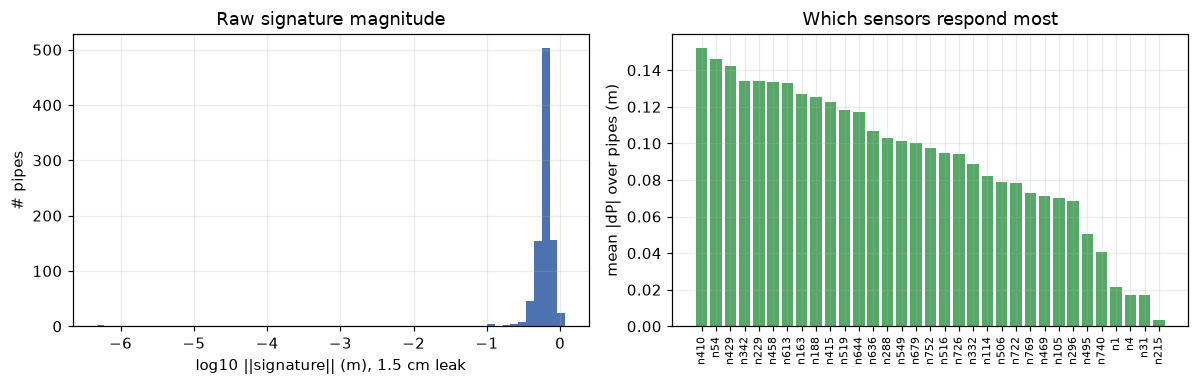

weakest 10 signatures (m):
p227    0.00000
p235    0.00000
p182    0.02444
p849    0.03926
p781    0.07088
p110    0.10798
p850    0.11128
p780    0.11507
p839    0.12050
p779    0.15891


In [3]:
norms = np.linalg.norm(sig_mean, axis=1)                 # raw norm (m) for a 1.5 cm leak
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].hist(np.log10(norms + 1e-9), bins=60, color='#4C72B0')
ax[0].set_xlabel('log10 ||signature|| (m), 1.5 cm leak'); ax[0].set_ylabel('# pipes'); ax[0].set_title('Raw signature magnitude')
resp = np.abs(sig_mean).mean(0); order = np.argsort(-resp)
ax[1].bar(range(33), resp[order], color='#55A868')
ax[1].set_xticks(range(33)); ax[1].set_xticklabels(np.array(sensors)[order], rotation=90, fontsize=7)
ax[1].set_ylabel('mean |dP| over pipes (m)'); ax[1].set_title('Which sensors respond most')
plt.tight_layout(); savefig('p1_signature_magnitude'); plt.show()
print('weakest 10 signatures (m):'); print(pd.Series(norms, index=pipes).nsmallest(10).round(5).to_string())

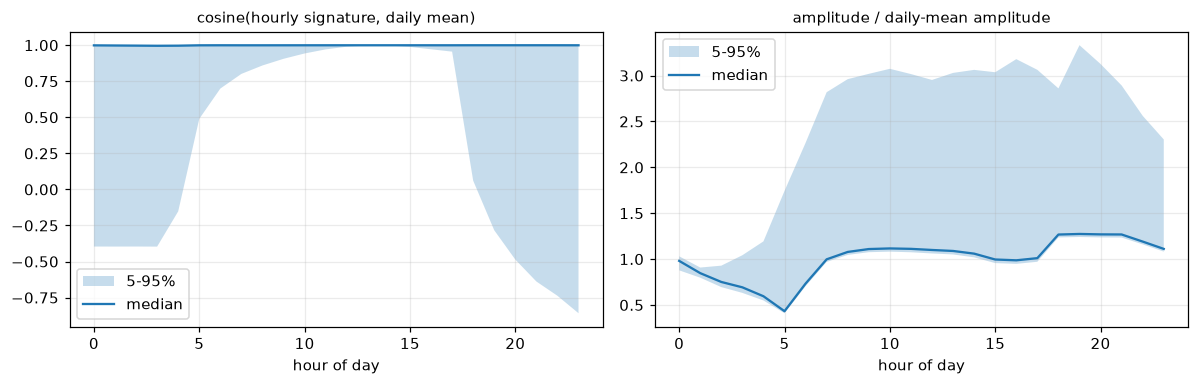

median over pipes of the worst-hour cosine: 0.995 | 5th percentile: -0.858
median over pipes of max/min hourly amplitude ratio: 2.96


In [4]:
def cosine(a, b, axis=-1):
    return (a * b).sum(axis) / (np.linalg.norm(a, axis=axis) * np.linalg.norm(b, axis=axis) + 1e-12)


strong = norms > np.quantile(norms, 0.25)                # cosine is meaningless for the weakest quarter
cos_h = cosine(psig[strong], sig_mean[strong][:, None, :])                 # (n, 24) shape of hour h vs daily mean
amp_h = np.linalg.norm(psig[strong], axis=2) / norms[strong][:, None]      # amplitude of hour h vs daily mean

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for a, M, t in ((ax[0], cos_h, 'cosine(hourly signature, daily mean)'), (ax[1], amp_h, 'amplitude / daily-mean amplitude')):
    q = np.quantile(M, [0.05, 0.5, 0.95], axis=0)
    a.fill_between(range(24), q[0], q[2], alpha=.25, label='5-95%'); a.plot(range(24), q[1], label='median')
    a.set_xlabel('hour of day'); a.set_title(t, fontsize=10); a.legend()
plt.tight_layout(); savefig('p1_hourly_variation'); plt.show()
print('median over pipes of the worst-hour cosine: %.3f | 5th percentile: %.3f' %
      (np.median(cos_h.min(1)), np.quantile(cos_h.min(1), 0.05)))
print('median over pipes of max/min hourly amplitude ratio: %.2f' % np.median(amp_h.max(1) / np.maximum(amp_h.min(1), 1e-9)))

<div dir="rtl" style="text-align:right">

**چطور بخوانیم:** اگر کسینوس ساعتی نزدیک ۱ (مثلاً بالاتر از ۰٫۹۵ تقریباً در همه ساعت‌ها) باشد، جهت امضا در شبانه‌روز پایدار است و میانگین روزانه برای خوشه‌بندی کافی است. اگر نسبت دامنه بزرگ باشد، باید در گزارش بنویسید که دامنه نشت به ساعت وابسته است و قدرت آشکارسازی شب و روز فرق دارد؛ شبکه اول باید ساعت روز را یا به‌صورت ورودی بگیرد یا از انحراف از خط پایه *وابسته به ساعت* استفاده کند. چون الگوی هفتگی تقاضا در امضای یک روز نیامده، این تقریب را صریحاً به‌عنوان محدودیت ذکر کنید (از «اشتباه‌های متداول» راهنما).

</div>

<div dir="rtl" style="text-align:right">

## ۳. قاعده مقیاس‌گذاری با مساحت روزنه

برای اینکه لازم نباشد هر اندازه را شبیه‌سازی کنیم، فرض می‌کنیم امضای یک نشت با قطر $D$ برابر است با $(D/1.5\,\text{cm})^2$ برابر امضای مرجع. اسکریپت `signatures.py` این قاعده را روی ۱۲ گره تصادفی و دو قطر (۰٫۸ و ۲٫۵ سانتی‌متر) آزموده است. هدف این بخش: **محدوده اعتماد** قاعده را بسنجیم (گام ۳ راهنما).

</div>

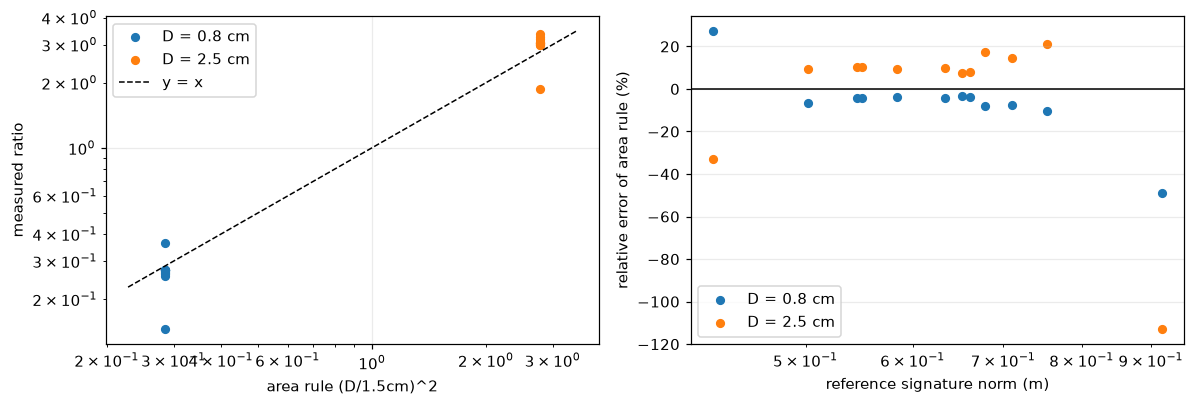

       count   mean    std    min    max
D                                       
0.008   12.0 -0.065  0.165 -0.489  0.273
0.025   12.0 -0.024  0.374 -1.130  0.211


In [5]:
scal = scal.copy()
scal['rel_err'] = scal['measured_ratio'] / scal['area_rule'] - 1
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for D, g in scal.groupby('D'):
    ax[0].scatter(g['area_rule'], g['measured_ratio'], label=f'D = {D * 100:.1f} cm', s=25)
lo, hi = scal['area_rule'].min() * 0.8, scal['area_rule'].max() * 1.25
ax[0].plot([lo, hi], [lo, hi], 'k--', lw=1, label='y = x')
ax[0].set_xscale('log'); ax[0].set_yscale('log'); ax[0].set_xlabel('area rule (D/1.5cm)^2'); ax[0].set_ylabel('measured ratio'); ax[0].legend()
for D, g in scal.groupby('D'):
    ax[1].scatter(g['ref_norm'], g['rel_err'] * 100, label=f'D = {D * 100:.1f} cm', s=25)
ax[1].axhline(0, color='k', lw=1); ax[1].set_xscale('log')
ax[1].set_xlabel('reference signature norm (m)'); ax[1].set_ylabel('relative error of area rule (%)'); ax[1].legend()
plt.tight_layout(); savefig('p1_scaling_check'); plt.show()
print(scal.groupby('D')['rel_err'].describe()[['count', 'mean', 'std', 'min', 'max']].round(3))

<div dir="rtl" style="text-align:right">

**چطور بخوانیم:** خطای نسبی کوچک و بدون روند یعنی قاعده مساحت در بازه ۰٫۸ تا ۲٫۵ سانتی‌متر قابل اعتماد است (بازه نشت‌های واقعی ۰٫۸۵ تا ۲٫۴ است و در داخل این بازه قرار دارد). اگر خطا برای گره‌های با امضای ضعیف (محور افقی سمت چپ) بزرگ‌تر شد، آن‌ها همان لوله‌هایی‌اند که به هر حال زیر نویز می‌افتند و مهم نیستند. تعداد گره‌های آزمون (۱۲) کم است؛ در گزارش «محدوده اعتماد» را با min و max بنویسید نه با انحراف معیار، و اگر زمان داشتید تعداد گره‌ها را افزایش دهید.

</div>

<div dir="rtl" style="text-align:right">

## ۴. مقایسه سیگنال با نویز و لوله‌های کم‌اثر

نویز روزبه‌روز ۳۳ حسگر تقریباً کاملاً در چند جهت مشترک (common-mode) متمرکز است. مقایسه اقلیدسی یا کسینوسی خام با آن جهت‌ها تحت‌الشعاع قرار می‌گیرد. پس امضا و نویز را در **فضای سفیدشده** (فاصله ماهالانوبیس نسبت به نویز واقعی میانگین ۶ ساعته) می‌سنجیم. در این بخش از `leaklib` استفاده می‌کنیم تا دقیقاً همان محاسبه `clusters.py` تکرار شود. سلول بازتولید با `assert` می‌سنجد که نتیجه با فایل‌های اسکریپت برابر باشد.

**نکته روش‌شناختی:** کوواریانس نویز از ساعت‌های بدون نشت *کل* سال برازش می‌شود، و این شامل ماه‌های اعتبارسنجی هم هست. چون فقط از ماسک «بدون نشت» استفاده می‌شود و برچسب نشت‌ها وارد خوشه‌بندی نمی‌شود، اثر آن ضعیف است. اگر خواستید سخت‌گیر باشید، برازش را به ماه‌های آموزش محدود کنید و حساسیت را گزارش کنید (جدول بخش ۹).

</div>

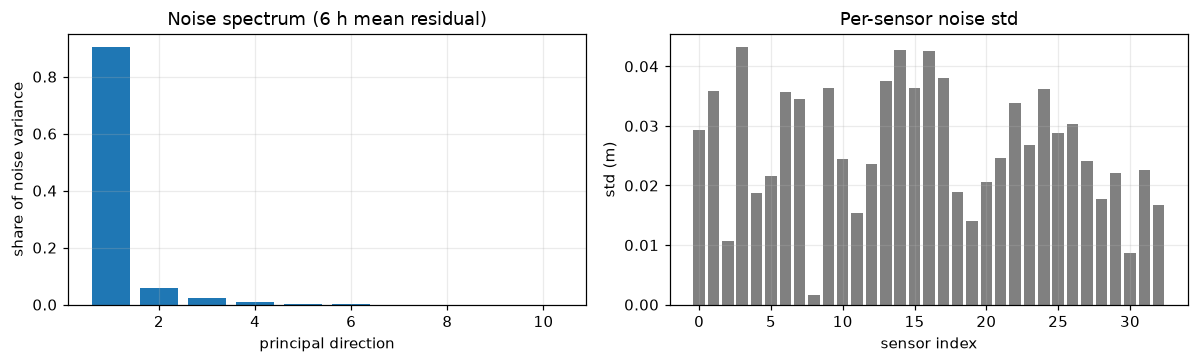

top-2 directions carry 96.4% of noise variance | per-sensor std: median 0.025 m, max 0.043 m


In [6]:
data = ll.load_folder(str(ROOT / 'historical_2018'))
lab  = pd.read_csv(ROOT / 'historical_2018' / 'labels.csv', index_col=0, parse_dates=True)
free = (lab['leak_active'].values == 0)
base = ll.Baseline().fit(data, free)
Wh   = base.whiten

ev = np.linalg.eigvalsh(base.noise6_cov)[::-1]; share = ev / ev.sum()
noise6 = np.sqrt(np.diag(base.noise6_cov))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].bar(range(1, 11), share[:10]); ax[0].set_xlabel('principal direction'); ax[0].set_ylabel('share of noise variance')
ax[0].set_title('Noise spectrum (6 h mean residual)')
ax[1].bar(range(ll.NS), noise6, color='gray'); ax[1].set_xlabel('sensor index'); ax[1].set_ylabel('std (m)'); ax[1].set_title('Per-sensor noise std')
plt.tight_layout(); savefig('p1_noise_spectrum'); plt.show()
print(f'top-2 directions carry {share[:2].sum():.1%} of noise variance | per-sensor std: median {np.median(noise6):.3f} m, max {noise6.max():.3f} m')

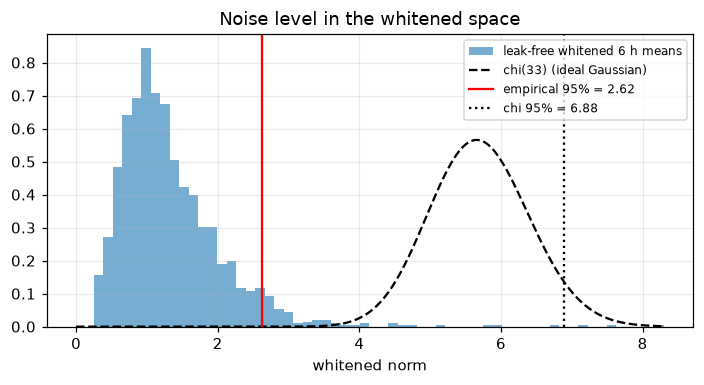

median whitened noise norm 1.18 (chi median 5.69)


In [7]:
R, _ = base.residuals(data)
M6 = ll.causal_mean(R[:, :ll.NS], 6 * ll.STEP)
fw = pd.Series(free.astype(float)).rolling(6 * ll.STEP, min_periods=6 * ll.STEP).min().values == 1   # whole 6 h window leak-free
noise_z = np.linalg.norm(M6[fw][::ll.STEP] @ Wh, axis=1)                                             # one sample per hour
assert np.isclose(np.quantile(noise_z, 0.95), THR, rtol=1e-6), 'noise threshold differs from clusters.py'

chi = stats.chi(df=ll.NS)
xs = np.linspace(0, max(noise_z.max(), chi.ppf(0.999)), 300)
fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.hist(noise_z, bins=60, density=True, alpha=.6, label='leak-free whitened 6 h means')
ax.plot(xs, chi.pdf(xs), 'k--', label=f'chi({ll.NS}) (ideal Gaussian)')
ax.axvline(THR, color='r', label=f'empirical 95% = {THR:.2f}'); ax.axvline(chi.ppf(0.95), color='k', ls=':', label=f'chi 95% = {chi.ppf(0.95):.2f}')
ax.set_xlabel('whitened norm'); ax.legend(fontsize=8); ax.set_title('Noise level in the whitened space')
plt.tight_layout(); savefig('p1_noise_norm'); plt.show()
print('median whitened noise norm %.2f (chi median %.2f)' % (np.median(noise_z), chi.median()))

<div dir="rtl" style="text-align:right">

**چطور بخوانیم:** اگر نویز سفیدشده دقیقاً گاوسی بود، نرم آن از توزیع $\chi_{33}$ پیروی می‌کرد. دم سنگین‌تر از $\chi_{33}$ یعنی آستانه تجربی (صدک ۹۵ام داده واقعی) از آستانه نظری بزرگ‌تر و محافظه‌کارانه‌تر است. این همان دلیلی است که آستانه را تجربی گرفته‌ایم. چون نمونه‌های ساعتی از میانگین‌های ۶ ساعته همپوشان‌اند و خودهمبسته‌اند، تعداد نمونه مؤثر کمتر از تعداد نمونه‌هاست و صدک ۹۵ام کمی نااطمینان است؛ این را در گزارش بنویسید.

</div>

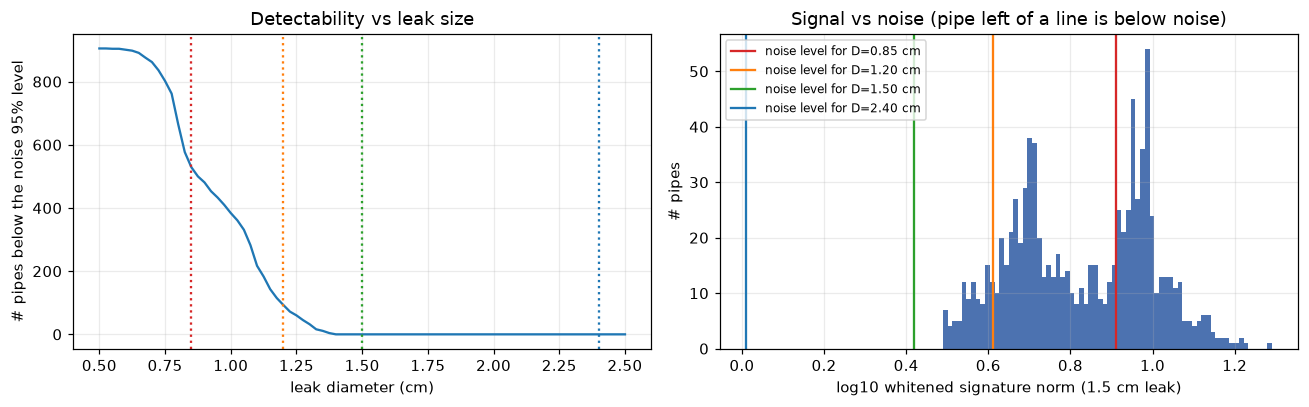

 D_cm  n_pipes_below_noise  share_%
 0.85                  529     58.5
 1.20                   93     10.3
 1.50                    0      0.0
 2.40                    0      0.0
low-visibility set used by clusters.py (below noise for a 1.2 cm leak): 93


In [8]:
# --- reproduce the whitened signatures exactly as clusters.py does
FLOW_SHARE = np.array([0.05, 0.475, 0.475])        # share of the extra inflow carried by (PUMP_1, p227, p235); assumption, see sec. 9


def whitened_signatures(share):
    res = np.stack([base.delta_residual(sig_mean[i:i + 1], pdq[i] * share[None])[0, :ll.NS] for i in range(len(pipes))])
    return res, res @ Wh


sig_res, Z = whitened_signatures(FLOW_SHARE)
z_norm = np.linalg.norm(Z, axis=1)
assert np.allclose(z_norm, details['z_norm_1p5cm'].values, rtol=1e-5, atol=1e-8), 'notebook diverged from clusters.py'
assert ((z_norm * (0.012 / 0.015) ** 2 >= THR) == det).all()
U = Z / (z_norm[:, None] + 1e-12)                  # unit "shape" vectors used for clustering

Ds = np.linspace(0.005, 0.025, 81)
n_under = [int((z_norm * (D / 0.015) ** 2 < THR).sum()) for D in Ds]
marks = ((0.0085, 'tab:red'), (0.012, 'tab:orange'), (0.015, 'tab:green'), (0.024, 'tab:blue'))
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].plot(Ds * 100, n_under)
for D, c in marks: ax[0].axvline(D * 100, ls=':', c=c)
ax[0].set_xlabel('leak diameter (cm)'); ax[0].set_ylabel('# pipes below the noise 95% level'); ax[0].set_title('Detectability vs leak size')
ax[1].hist(np.log10(z_norm + 1e-12), bins=70, color='#4C72B0')
for D, c in marks:
    ax[1].axvline(np.log10(THR * (0.015 / D) ** 2), color=c, label=f'noise level for D={D * 100:.2f} cm')
ax[1].set_xlabel('log10 whitened signature norm (1.5 cm leak)'); ax[1].set_ylabel('# pipes'); ax[1].legend(fontsize=8)
ax[1].set_title('Signal vs noise (pipe left of a line is below noise)')
plt.tight_layout(); savefig('p1_signal_vs_noise'); plt.show()

tab_noise = pd.DataFrame([(D * 100, int((z_norm * (D / 0.015) ** 2 < THR).sum())) for D, _ in marks], columns=['D_cm', 'n_pipes_below_noise'])
tab_noise['share_%'] = (100 * tab_noise['n_pipes_below_noise'] / len(pipes)).round(1)
print(tab_noise.to_string(index=False))
print('low-visibility set used by clusters.py (below noise for a 1.2 cm leak):', int((~det).sum()))

<div dir="rtl" style="text-align:right">

**چطور بخوانیم:** نمودار چپ می‌گوید با کوچک شدن نشت چند لوله از دید شبکه خارج می‌شود. چون سیگنال با $D^2$ رشد می‌کند، منحنی در قطرهای کوچک تند بالا می‌رود. این لوله‌ها «غیرقابل آشکارسازی»اند و باید جداگانه (بخش ۶) گزارش شوند و نه بی‌توضیح حذف. توجه کنید «کم‌اثر بودن» به قطر وابسته است. مجموعه‌ای که `clusters.py` با آن خوشه می‌سازد (۱٫۲ سانتی‌متر) انتخابی میانی است و باید در گزارش توجیه شود.

**حساسیت به `FLOW_SHARE`:** مقدار این ثابت (سهم هر حسگر جریان از افزایش ورودی) در کد حدسی است. سلول بعد نشان می‌دهد نتیجه چقدر به آن وابسته است.

</div>

In [9]:
alts = {'baseline [.05, .475, .475]': FLOW_SHARE,
        'pump 0, tanks .5/.5': np.array([0., .5, .5]),
        'pump .2, tanks .4/.4': np.array([.2, .4, .4]),
        'equal thirds': np.ones(3) / 3}
rows = []
for name, sh in alts.items():
    _, Za = whitened_signatures(sh)
    za = np.linalg.norm(Za, axis=1)
    rows.append(dict(flow_share=name,
                     n_low_visibility_1p2cm=int((za * (0.012 / 0.015) ** 2 < THR).sum()),
                     median_cos_to_baseline=float(np.median(cosine(Za[det], Z[det])))))
flow_sens = pd.DataFrame(rows)
print(flow_sens.round(3).to_string(index=False))

                flow_share  n_low_visibility_1p2cm  median_cos_to_baseline
baseline [.05, .475, .475]                      93                   1.000
       pump 0, tanks .5/.5                      66                   0.999
      pump .2, tanks .4/.4                     172                   0.985
              equal thirds                     179                   0.946


<div dir="rtl" style="text-align:right">

**چطور بخوانیم:** اگر شمار لوله‌های کم‌اثر کم تغییر کند و کسینوس میانه نزدیک ۱ بماند، نتایج نسبت به این حدس مقاوم‌اند. در غیر این صورت، سهم جریان‌ها را باید از داده واقعی (مثلاً رگرسیون تغییر جریان‌های هر منبع بر افت فشار در ساعت‌های دارای نشت) تخمین بزنید و در گزارش به عنوان خطر اصلی ذکر کنید.

</div>

<div dir="rtl" style="text-align:right">

## ۵. انتخاب K، کیفیت و پایداری خوشه‌ها

**شکل کار:** امضای سفیدشده هر لوله به طول واحد برده می‌شود تا *شکل* ملاک باشد و k-means روی لوله‌های قابل آشکارسازی اجرا می‌شود (روی کره واحد، k-means تقریباً معادل خوشه‌بندی با کسینوس است). لوله‌های کم‌اثر بعداً به نزدیک‌ترین مرکز نسبت داده می‌شوند.

**معیار انتخاب K:** تلاش جست‌وجوی مورد انتظار (همان معیار ارزیابی: سهم لوله‌هایی که تا رسیدن به خوشه درست باید بازرسی شوند) با افزایش K تقریباً یکنواخت کم می‌شود، پس `argmin` همیشه بزرگ‌ترین K را برمی‌گزیند. قاعده اسکریپت: *کوچک‌ترین K که تلاش مورد انتظار آن کمتر از ۰٫۱۰ باشد*، چون هر خوشه اضافه یک کلاس دیگر برای مکان‌یابی است که فقط ۲۰ نشت واقعی دارد.

</div>

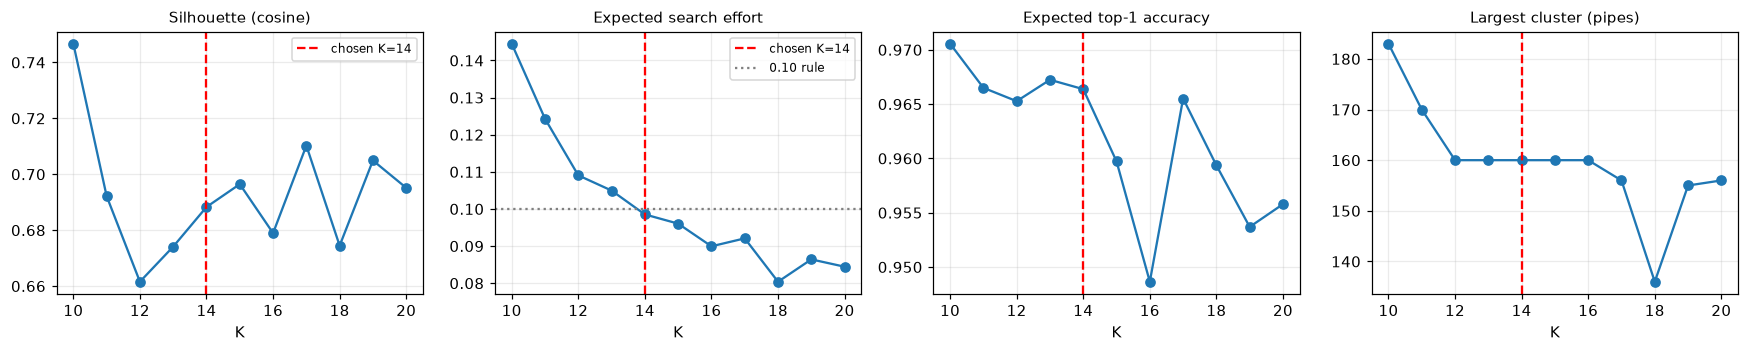

 K  silhouette  exp_search_effort  exp_top1  max_cluster  marginal_gain
10       0.747              0.145     0.971          183            NaN
11       0.692              0.124     0.967          170          0.020
12       0.662              0.109     0.965          160          0.015
13       0.674              0.105     0.967          160          0.004
14       0.688              0.099     0.966          160          0.006
15       0.696              0.096     0.960          160          0.002
16       0.679              0.090     0.949          160          0.006
17       0.710              0.092     0.966          156         -0.002
18       0.674              0.080     0.959          136          0.012
19       0.705              0.086     0.954          155         -0.006
20       0.695              0.084     0.956          156          0.002


In [10]:
fig, ax = plt.subplots(1, 4, figsize=(16, 3.3))
for a, col, t in zip(ax, ['silhouette', 'exp_search_effort', 'exp_top1', 'max_cluster'],
                     ['Silhouette (cosine)', 'Expected search effort', 'Expected top-1 accuracy', 'Largest cluster (pipes)']):
    a.plot(ktab['K'], ktab[col], 'o-'); a.axvline(K, color='r', ls='--', label=f'chosen K={K}'); a.set_title(t, fontsize=10); a.set_xlabel('K')
ax[1].axhline(0.10, color='gray', ls=':', label='0.10 rule'); ax[1].legend(fontsize=8); ax[0].legend(fontsize=8)
plt.tight_layout(); savefig('p1_k_selection'); plt.show()
print(ktab.assign(marginal_gain=-ktab['exp_search_effort'].diff()).round(3).to_string(index=False))

<div dir="rtl" style="text-align:right">

**چطور بخوانیم:** ستون `marginal_gain` نشان می‌دهد هر خوشه اضافه چقدر از تلاش مورد انتظار می‌کاهد. توجیه K در گزارش باید سه جزء داشته باشد: (۱) مقدار تلاش مورد انتظار در K انتخاب‌شده، (۲) سود حاشیه‌ای ناچیز برای K بزرگ‌تر، (۳) نبود بن‌بست در نمونه‌های واقعی (بخش ۷: خوشه بیش از حد ریز یعنی کلاس‌های بدون نمونه واقعی). سیلوئت در این مسئله نمایانگر ساختار ضعیف‌تری از انتظار است چون لوله‌های همسایه پیوسته در فضا می‌افتند؛ تکیه اصلی روی معیار تلاش جست‌وجو است که همان معیار ارزیابی است.

</div>

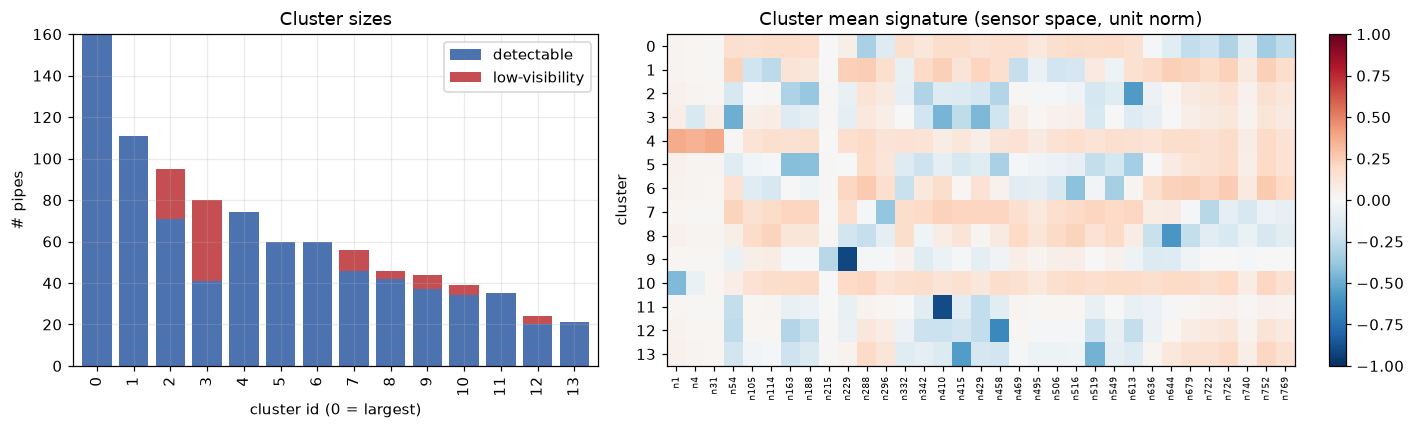

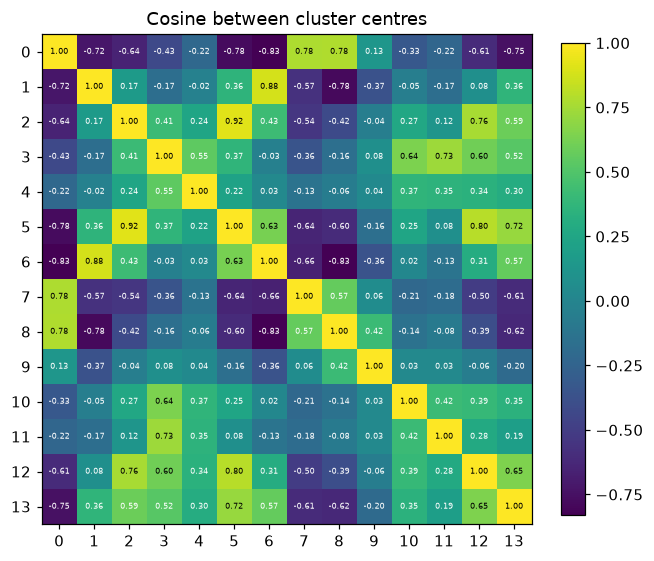

most similar cluster pairs (likely to be confused by the localiser):
  clusters 2 & 5: cos = 0.921
  clusters 1 & 6: cos = 0.881
  clusters 5 & 12: cos = 0.803
  clusters 0 & 8: cos = 0.782
  clusters 0 & 7: cos = 0.775


In [11]:
ct = pd.DataFrame({'detectable': [int(((cl == k) & det).sum()) for k in range(K)],
                   'low-visibility': [int(((cl == k) & ~det).sum()) for k in range(K)]})
fig, ax = plt.subplots(1, 2, figsize=(13, 4), gridspec_kw={'width_ratios': [1, 1.3]})
ct.plot.bar(stacked=True, ax=ax[0], color=['#4C72B0', '#C44E52'], width=.8)
ax[0].set_xlabel('cluster id (0 = largest)'); ax[0].set_ylabel('# pipes'); ax[0].set_title('Cluster sizes')

# physical profile of each cluster: mean (unwhitened) residual signature in sensor space, unit norm
prof = np.stack([sig_res[(cl == k) & det].mean(0) if ((cl == k) & det).any() else np.zeros(ll.NS) for k in range(K)])
prof /= (np.linalg.norm(prof, axis=1, keepdims=True) + 1e-12)
im = ax[1].imshow(prof, aspect='auto', cmap='RdBu_r', vmin=-1, vmax=1)
ax[1].set_xticks(range(ll.NS)); ax[1].set_xticklabels(sensors[:ll.NS], rotation=90, fontsize=6)
ax[1].set_yticks(range(K)); ax[1].set_ylabel('cluster'); ax[1].set_title('Cluster mean signature (sensor space, unit norm)'); ax[1].grid(False)
plt.colorbar(im, ax=ax[1], fraction=.03)
plt.tight_layout(); savefig('p1_cluster_sizes_profiles'); plt.show()

S = C @ C.T                                            # cosine between cluster centres (whitened space)
fig, ax = plt.subplots(figsize=(6.2, 5.2))
im = ax.imshow(S, cmap='viridis', vmin=min(0, S.min()), vmax=1); ax.grid(False)
for i in range(K):
    for j in range(K):
        ax.text(j, i, f'{S[i, j]:.2f}', ha='center', va='center', fontsize=5.5, color='w' if S[i, j] < .6 else 'k')
ax.set_xticks(range(K)); ax.set_yticks(range(K)); ax.set_title('Cosine between cluster centres'); plt.colorbar(im, fraction=.04)
plt.tight_layout(); savefig('p1_centroid_cosine'); plt.show()
iu = np.triu_indices(K, 1)
print('most similar cluster pairs (likely to be confused by the localiser):')
for s, i, j in sorted(zip(S[iu], iu[0], iu[1]), reverse=True)[:5]:
    print(f'  clusters {i} & {j}: cos = {s:.3f}')

nearest centre == assigned cluster for 100.0% of pipes (0 disagree; 0 of them have a ~zero signature)


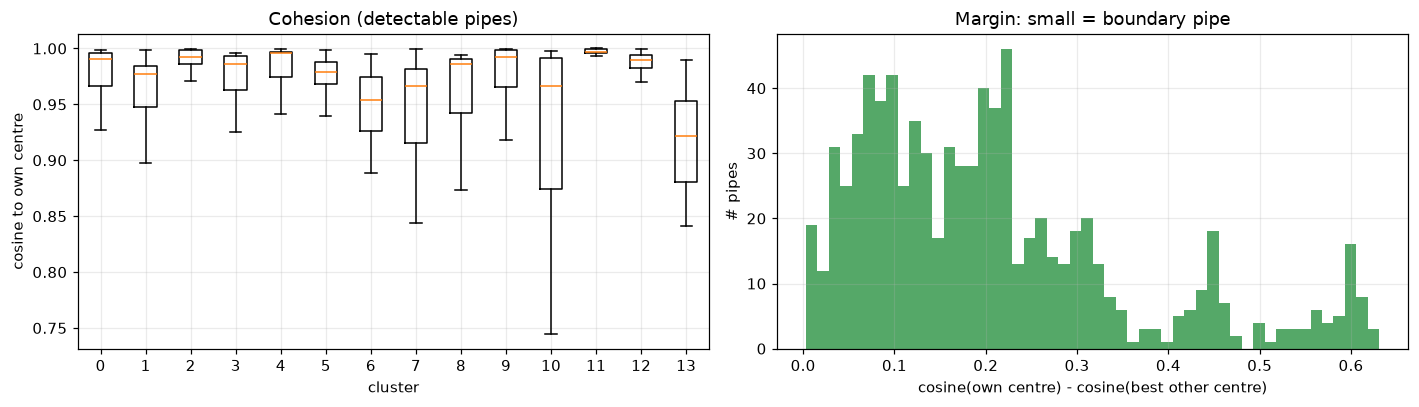

boundary pipes (detectable): margin < 0.02: 3.1% | margin < 0.05: 9.7%


In [12]:
sc = U @ C.T                                            # cosine of every pipe to every centre
rows_i = np.arange(len(pipes))
own = sc[rows_i, cl]
sc_other = sc.copy(); sc_other[rows_i, cl] = -np.inf
margin = own - sc_other.max(1)                          # >0: own centre is the closest; small = boundary pipe
agree = (sc.argmax(1) == cl)
print(f'nearest centre == assigned cluster for {agree.mean():.1%} of pipes ({(~agree).sum()} disagree; '
      f'{int(((~agree) & (z_norm < 1e-6)).sum())} of them have a ~zero signature)')

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
ax[0].boxplot([own[(cl == k) & det] if ((cl == k) & det).any() else [np.nan] for k in range(K)], showfliers=False)
ax[0].set_xticklabels(range(K)); ax[0].set_xlabel('cluster'); ax[0].set_ylabel('cosine to own centre'); ax[0].set_title('Cohesion (detectable pipes)')
ax[1].hist(margin[det], bins=50, color='#55A868'); ax[1].set_xlabel('cosine(own centre) - cosine(best other centre)')
ax[1].set_ylabel('# pipes'); ax[1].set_title('Margin: small = boundary pipe')
plt.tight_layout(); savefig('p1_cohesion_margin'); plt.show()
print('boundary pipes (detectable): margin < 0.02: %.1f%% | margin < 0.05: %.1f%%' %
      (100 * (margin[det] < 0.02).mean(), 100 * (margin[det] < 0.05).mean()))

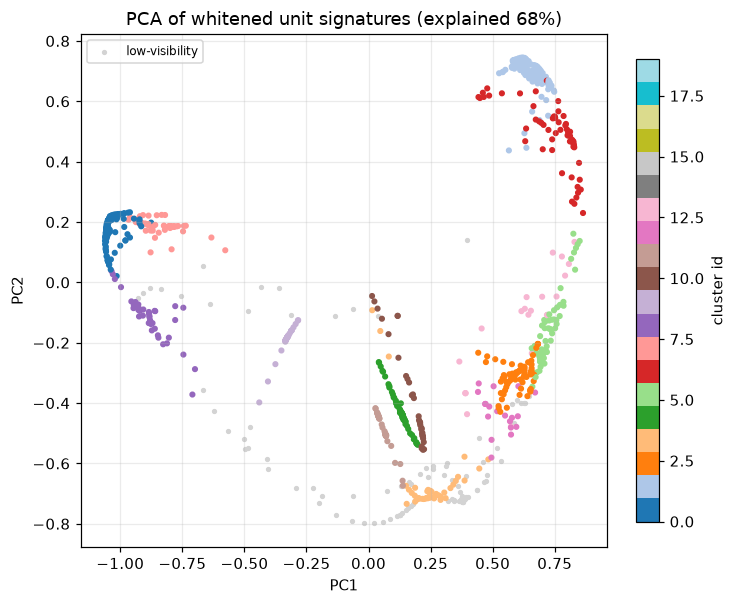

In [13]:
pca = PCA(2).fit(U[det]); P2 = pca.transform(U)
fig, ax = plt.subplots(figsize=(6.8, 5.6))
ax.scatter(*P2[~det].T, s=6, c='lightgray', label='low-visibility')
s_ = ax.scatter(*P2[det].T, s=9, c=cl[det], cmap='tab20', vmin=0, vmax=19)
ax.set_title(f'PCA of whitened unit signatures (explained {pca.explained_variance_ratio_.sum():.0%})')
ax.set_xlabel('PC1'); ax.set_ylabel('PC2'); ax.legend(fontsize=8)
cb = plt.colorbar(s_, fraction=.04); cb.set_label('cluster id')
plt.tight_layout(); savefig('p1_pca_clusters'); plt.show()

<div dir="rtl" style="text-align:right">

### پایداری خوشه‌ها و لوله‌های مشابه

**پایداری:** اگر دوباره با seed دیگر یا الگوریتم دیگری (Ward) خوشه بسازیم، چقدر تقسیم‌بندی شبیه می‌ماند؟ از Adjusted Rand Index (ARI) روی لوله‌های قابل آشکارسازی استفاده می‌کنیم (۱ یعنی کاملاً یکسان و مستقل از شماره‌گذاری خوشه‌ها).

**لوله‌های مشابه:** برای هر لوله، شبیه‌ترین لوله دیگر (کسینوس در فضای سفیدشده). جفت‌های با کسینوس خیلی بالا را حتی بی‌نویز هم نمی‌توان از هم جدا کرد؛ این‌ها سقف دقت هر مکان‌یابی‌اند.

</div>

                          method   ARI
reproduce seed 0 (should be 1.0) 1.000
                   kmeans seed 1 0.997
                   kmeans seed 2 0.881
                   kmeans seed 3 0.887
                   kmeans seed 4 0.991
                   kmeans seed 5 0.882
                            ward 0.814


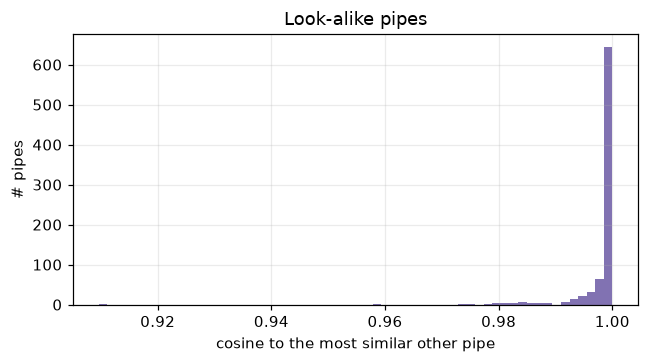

 cosine >=  share_of_detectable_pipes_%
     0.900                        100.0
     0.950                         99.9
     0.990                         95.9
     0.999                         73.6
nearest look-alike lies in a DIFFERENT cluster for 1.4% of detectable pipes


In [14]:
Ud, ref = U[det], cl[det]
km0 = KMeans(K, n_init=20, random_state=0).fit(Ud)
rows = [('reproduce seed 0 (should be 1.0)', adjusted_rand_score(ref, km0.labels_))]
for seed in range(1, 6):
    rows.append((f'kmeans seed {seed}', adjusted_rand_score(ref, KMeans(K, n_init=20, random_state=seed).fit(Ud).labels_)))
rows.append(('ward', adjusted_rand_score(ref, AgglomerativeClustering(n_clusters=K, linkage='ward').fit(Ud).labels_)))
ari = pd.DataFrame(rows, columns=['method', 'ARI'])
print(ari.round(3).to_string(index=False))
if rows[0][1] < 0.999:
    warnings.warn('seed-0 k-means does not reproduce clusters.csv (different sklearn version / platform?)')

Sim = Ud @ Ud.T; np.fill_diagonal(Sim, -1)
nn_val, nn_idx = Sim.max(1), Sim.argmax(1)
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.hist(nn_val, bins=60, color='#8172B2'); ax.set_xlabel('cosine to the most similar other pipe'); ax.set_ylabel('# pipes'); ax.set_title('Look-alike pipes')
plt.tight_layout(); savefig('p1_lookalikes'); plt.show()
twins = pd.DataFrame({'cosine >=': [0.9, 0.95, 0.99, 0.999]})
twins['share_of_detectable_pipes_%'] = [round(100 * float((nn_val >= t).mean()), 1) for t in twins['cosine >=']]
print(twins.to_string(index=False))
print('nearest look-alike lies in a DIFFERENT cluster for %.1f%% of detectable pipes' % (100 * (ref[nn_idx] != ref).mean()))

<div dir="rtl" style="text-align:right">

**چطور بخوانیم:** ARI بالا (مثلاً بالاتر از حدود ۰٫۸) یعنی ساختار خوشه‌ها به seed و الگوریتم وابسته نیست. ARI پایین‌تر طبیعی است، چون فضای امضاها پیوسته است و مرز خوشه‌ها قراردادی. در آن صورت می‌گویید برچسب‌های خوشه «تقسیم‌بندی یک پیوستار» است و دقت رتبه اول سقف دارد، که برای همین معیار ارزیابی تلاش جست‌وجو (کل رتبه‌بندی) را در نظر می‌گیرد و نه فقط رتبه اول. دو لوله مشابه که در دو خوشه متفاوتند، منبع اصلی خطای رتبه اول‌اند؛ سهم آن‌ها در خروجی آخر چاپ شد.

</div>

<div dir="rtl" style="text-align:right">

## ۶. لوله‌های کم‌اثر و اثرشان بر خوشه‌ها

لوله‌هایی که سیگنالشان زیر نویز است برچسب خوشه معنادار ندارند. `clusters.csv` باید برای *همه* ۹۰۵ لوله باشد، پس `clusters.py` آن‌ها را به نزدیک‌ترین مرکز می‌دهد. دو خطر وجود دارد که این بخش می‌سنجد:

1. لوله‌هایی با امضای دقیقاً صفر (مثل گره‌های کنار شیر فشارشکن یا خطوط اصلی مخزن) بردار واحدشان صفر می‌شود و `argmax` روی کسینوس‌های صفر همیشه اولین مرکز را برمی‌گرداند؛ در نتیجه همه آن‌ها در یک خوشه تلنبار می‌شوند. چون شماره‌گذاری بعداً بر اساس اندازه عوض می‌شود، این خوشه معمولاً بزرگ‌ترین خوشه (شناسه ۰) می‌شود.
2. اندازه خوشه (که شامل لوله‌های کم‌اثر است) در مخرج و صورت معیار «تلاش جست‌وجو» می‌آید. تلنبار شدن لوله‌های بی‌سیگنال در یک خوشه هزینه جست‌وجوی آن خوشه را بزرگ می‌کند.

</div>

In [15]:
low = ~det
zero_like = z_norm < 1e-6
print(f'low-visibility pipes: {int(low.sum())} of {len(pipes)} ({100 * low.mean():.1f}%) | ~zero signature: {int(zero_like.sum())}')
print('where the ~zero-signature pipes went:', pd.Series(cl[zero_like]).value_counts().to_dict())
print('where all low-visibility pipes went :', pd.Series(cl[low]).value_counts().sort_index().to_dict())
frac_low = pd.Series({k: (low & (cl == k)).sum() / sizes[k] for k in range(K)})
print('share of low-visibility pipes inside each cluster (%):', (100 * frac_low).round(0).astype(int).to_dict())

lowdf = details.loc[low, ['pipe_id', 'cluster', 'z_norm_1p5cm', 'z_norm_0p85cm']].sort_values('z_norm_1p5cm')
lowdf.to_csv(ART / 'low_visibility_pipes.csv', index=False)     # appendix list for the report
print('\nweakest 10 pipes (appendix list saved to artifacts/low_visibility_pipes.csv):')
print(lowdf.head(10).round(3).to_string(index=False))
if len(no_sig):
    print('\npipes with NO signature at all (both ends are reservoirs/tanks):', list(no_sig))

low-visibility pipes: 93 of 905 (10.3%) | ~zero signature: 0
where the ~zero-signature pipes went: {}
where all low-visibility pipes went : {2: 24, 3: 39, 7: 10, 8: 4, 9: 7, 10: 5, 12: 4}
share of low-visibility pipes inside each cluster (%): {0: 0, 1: 0, 2: 25, 3: 49, 4: 0, 5: 0, 6: 0, 7: 18, 8: 9, 9: 16, 10: 13, 11: 0, 12: 17, 13: 0}

weakest 10 pipes (appendix list saved to artifacts/low_visibility_pipes.csv):
pipe_id  cluster  z_norm_1p5cm  z_norm_0p85cm
    p57        3         3.085          0.991
   p683        3         3.098          0.995
   p681        9         3.106          0.997
   p688        3         3.109          0.998
   p779        7         3.121          1.002
   p686        9         3.149          1.011
   p780       10         3.153          1.012
   p684        3         3.170          1.018
   p682        9         3.203          1.029
   p689        3         3.205          1.029


<div dir="rtl" style="text-align:right">

**چطور بخوانیم:** اگر لوله‌های با سیگنال صفر یا خیلی ضعیف بخش بزرگی از یک خوشه‌اند (به‌ویژه خوشه ۰)، بهتر است در `clusters.py` آن‌ها را عمداً به خوشه‌ای تخصیص دهید که هزینه جست‌وجوی کمتری دارد (مثلاً کوچک‌ترین خوشه یا نزدیک‌ترین مرکز بر اساس *امضای خام نرمال‌شده*) و علت را در گزارش بنویسید (صورت پروژه اجازه تغییر `clusters.csv` را به شرط ذکر علت می‌دهد). برای ارزیابی، نشت در این لوله‌ها به هر حال «تشخیص داده‌نشده» حساب می‌شود، پس برچسب‌شان فقط روی صورت و مخرج هزینه دیگر نشت‌ها اثر می‌گذارد.

</div>

<div dir="rtl" style="text-align:right">

## ۷. نگاشت ۲۰ نشت واقعی به خوشه‌ها

لوله هر نشت در `leaks.csv` را با `clusters.csv` به خوشه نگاشت می‌کنیم. سه چیز برای بخش‌های بعدی مهم است: (۱) کدام خوشه‌ها نمونه واقعی ندارند (برای آن‌ها داده مصنوعی لازم است و اعتبارسنجی واقعی ممکن نیست)، (۲) کدام نشت‌ها در اندازه خودشان هم زیر نویزند، (۳) نشت‌های همپوشان در خوشه‌های متفاوت؛ اسکریپت ارزیابی هر نشت را جدا می‌سنجد و یک خوشه نمی‌تواند رتبه اول هر دو باشد.

</div>

,leak_id,pipe_id,type,D_cm,cluster,z_at_D,z_over_noise,visible_at_own_size
0,L01,p262,abrupt,2.27,10,11.23,4.29,True
1,L02,p420,abrupt,2.06,3,6.56,2.50,True
2,L03,p446,abrupt,2.04,1,14.91,5.69,True
3,L04,p323,abrupt,2.18,11,13.68,5.22,True
4,L05,p75,abrupt,1.79,9,12.68,4.84,True
5,L06,p732,incipient,1.45,0,6.59,2.52,True
6,L07,p382,incipient,2.09,3,7.36,2.81,True
7,L08,p835,incipient,1.97,7,16.73,6.38,True
8,L09,p859,abrupt,1.98,0,20.20,7.71,True
9,L10,p9,incipient,1.75,3,5.92,2.26,True


clusters with real leaks: 11 of 14 | clusters WITHOUT any real leak: [2, 6, 13]
pipes inside empty clusters: 176 (19.4% of the network)
clusters with exactly one real leak (a single event cannot be split between train/validation): [1, 4, 10, 11, 12]
real leaks below the noise level at their own size: []


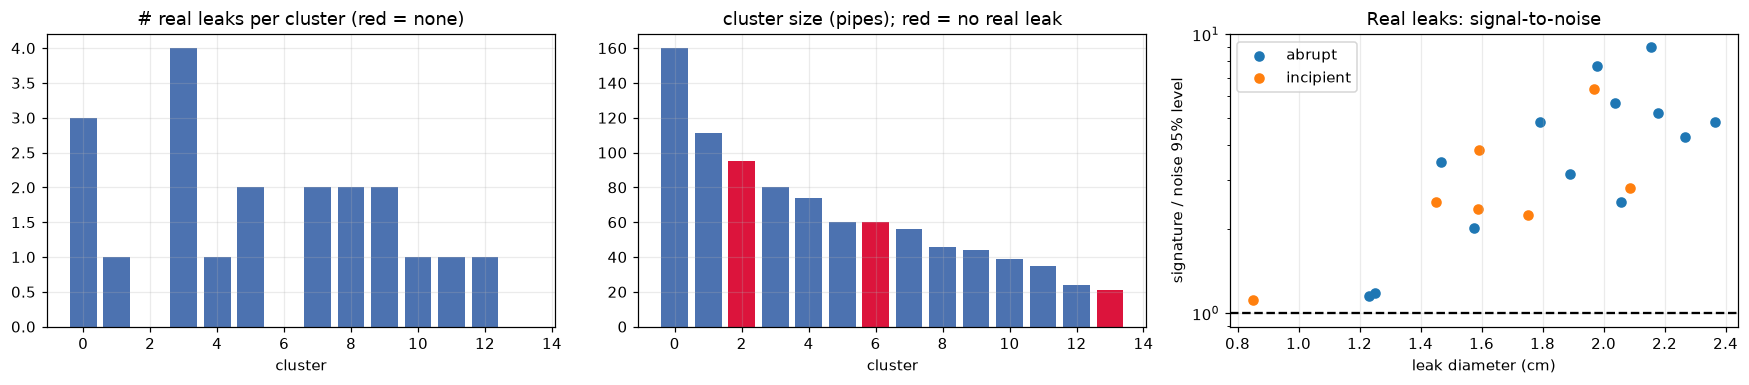

In [16]:
cm = leaks.copy()
cm['D_cm'] = cm['diameter_m'] * 100
cm['z_over_noise'] = cm['z_at_D'] / THR                    # >1: above the 95% noise level at its own size
cm['visible_at_own_size'] = cm['z_over_noise'] >= 1
display(cm[['leak_id', 'pipe_id', 'type', 'D_cm', 'cluster', 'z_at_D', 'z_over_noise', 'visible_at_own_size']].round(2))

cnt = cm['cluster'].value_counts().reindex(range(K), fill_value=0)
empty = cnt[cnt == 0].index.tolist()
pipes_in_empty = int(sizes[empty].sum())
print(f'clusters with real leaks: {int((cnt > 0).sum())} of {K} | clusters WITHOUT any real leak: {empty}')
print(f'pipes inside empty clusters: {pipes_in_empty} ({100 * pipes_in_empty / 905:.1f}% of the network)')
print('clusters with exactly one real leak (a single event cannot be split between train/validation):', cnt[cnt == 1].index.tolist())
print('real leaks below the noise level at their own size:', cm.loc[~cm['visible_at_own_size'], 'leak_id'].tolist())

cols = ['crimson' if c == 0 else '#4C72B0' for c in cnt.values]
fig, ax = plt.subplots(1, 3, figsize=(16, 3.6))
ax[0].bar(range(K), cnt.values, color=cols); ax[0].set_title('# real leaks per cluster (red = none)'); ax[0].set_xlabel('cluster')
ax[1].bar(range(K), sizes, color=cols); ax[1].set_title('cluster size (pipes); red = no real leak'); ax[1].set_xlabel('cluster')
for t, g in cm.groupby('type'):
    ax[2].scatter(g['D_cm'], g['z_over_noise'], label=t, s=35)
ax[2].axhline(1, color='k', ls='--'); ax[2].set_yscale('log'); ax[2].set_xlabel('leak diameter (cm)')
ax[2].set_ylabel('signature / noise 95% level'); ax[2].set_title('Real leaks: signal-to-noise'); ax[2].legend()
plt.tight_layout(); savefig('p1_real_leaks'); plt.show()

In [17]:
pairs = []
for i, a in leaks.iterrows():
    for j, b in leaks.iterrows():
        if i < j and a['start'] < b['end'] and b['start'] < a['end']:
            ov_h = (min(a['end'], b['end']) - max(a['start'], b['start'])).total_seconds() / 3600
            pairs.append((a['leak_id'], b['leak_id'], int(a['cluster']), int(b['cluster']), round(ov_h, 1)))
ov = pd.DataFrame(pairs, columns=['leak_a', 'leak_b', 'cluster_a', 'cluster_b', 'overlap_h'])
ov['same_cluster'] = ov['cluster_a'] == ov['cluster_b']
print(f'{len(ov)} overlapping leak pairs; {int((~ov["same_cluster"]).sum())} of them are in DIFFERENT clusters')
display(ov.sort_values('overlap_h', ascending=False).head(15))

10 overlapping leak pairs; 10 of them are in DIFFERENT clusters


,leak_a,leak_b,cluster_a,cluster_b,overlap_h,same_cluster
6,L13,L16,9,8,312.8,False
4,L13,L14,9,4,279.4,False
7,L13,L17,9,8,202.9,False
3,L08,L09,7,0,124.4,False
5,L13,L15,9,3,123.0,False
8,L13,L18,9,5,111.5,False
0,L01,L02,10,3,99.5,False
9,L13,L19,9,12,57.8,False
1,L02,L03,3,1,45.6,False
2,L07,L08,3,7,32.4,False


<div dir="rtl" style="text-align:right">

**چطور بخوانیم:** برای هر جفت همپوشان با خوشه‌های متفاوت، در آن بازه فقط یکی از دو نشت می‌تواند «رتبه اول» را داشته باشد؛ پس دقت انتخاب اول این رخدادها از نظر ساختاری از ۱۰۰٪ کمتر است و باید در تحلیل نتایج بیاید (صورت پروژه صریحاً این را می‌خواهد). خوشه‌هایی که فقط یک نشت واقعی دارند، در تفکیک بر اساس رخداد نمی‌توانند هم در آموزش و هم در اعتبارسنجی باشند؛ این روی طراحی تقسیم داده (بخش ۲) اثر دارد.

</div>

<div dir="rtl" style="text-align:right">

## ۸. خلاصه اعداد برای گزارش

سلول بعد اعداد مهم بخش ۱ را از همین اجرا استخراج و به‌صورت متن آماده می‌کند تا هنگام نوشتن گزارش کپی کنید. اعداد را بازبینی کنید و متن را با نظر خودتان تکمیل کنید.

</div>

In [18]:
r = ktab.set_index('K').loc[K]
ward_ari = float(ari.set_index('method').loc['ward', 'ARI'])
text = f"""<div dir="rtl" style="text-align:right">

**خلاصه اعداد بخش ۱**

- تعداد خوشه‌ها **K = {K}**؛ اندازه خوشه‌ها از {sizes.min()} تا {sizes.max()} لوله. تلاش جست‌وجوی مورد انتظار در شبیه‌سازی: {r['exp_search_effort']:.3f}؛ دقت مورد انتظار رتبه اول: {r['exp_top1']:.2f}؛ سیلوئت: {r['silhouette']:.2f}.
- آستانه نویز (صدک ۹۵ام نرم سفیدشده): {THR:.2f}. بیشترین سهم واریانس نویز در دو جهت اصلی: {share[:2].sum():.0%}.
- لوله‌های زیر نویز برای نشت ۱٫۲ سانتی‌متری: **{int((~det).sum())}** از {len(pipes)} ({100 * (~det).mean():.1f}٪). برای ۰٫۸۵ سانتی‌متر: {int(tab_noise.loc[0, 'n_pipes_below_noise'])}؛ برای ۲٫۴ سانتی‌متر: {int(tab_noise.loc[3, 'n_pipes_below_noise'])}.
- پایداری خوشه‌ها: ARI نسبت به Ward برابر {ward_ari:.2f}؛ میانه ARI نسبت به seedهای دیگر {ari.iloc[1:6]['ARI'].median():.2f}. {100 * (margin[det] < 0.05).mean():.0f}٪ لوله‌ها حاشیه کمتر از ۰٫۰۵ تا خوشه دوم دارند.
- لوله‌های مشابه: {100 * float((nn_val >= 0.99).mean()):.0f}٪ لوله‌های قابل آشکارسازی لوله دیگری با کسینوس ≥ ۰٫۹۹ دارند.
- ۲۰ نشت واقعی در {int((cnt > 0).sum())} خوشه از {K} قرار می‌گیرند. خوشه‌های بدون نمونه واقعی: {empty if empty else 'ندارد'} (حدود {100 * pipes_in_empty / 905:.0f}٪ لوله‌ها).
- نشت‌های واقعی زیر نویز در اندازه خودشان: {cm.loc[~cm['visible_at_own_size'], 'leak_id'].tolist() or 'ندارد'}.
- جفت نشت‌های همپوشان در خوشه‌های متفاوت: {int((~ov['same_cluster']).sum())} (سقف ساختاری برای دقت رتبه اول).

</div>"""
display(Markdown(text))

<div dir="rtl" style="text-align:right">

**خلاصه اعداد بخش ۱**

- تعداد خوشه‌ها **K = 14**؛ اندازه خوشه‌ها از 21 تا 160 لوله. تلاش جست‌وجوی مورد انتظار در شبیه‌سازی: 0.099؛ دقت مورد انتظار رتبه اول: 0.97؛ سیلوئت: 0.69.
- آستانه نویز (صدک ۹۵ام نرم سفیدشده): 2.62. بیشترین سهم واریانس نویز در دو جهت اصلی: 96%.
- لوله‌های زیر نویز برای نشت ۱٫۲ سانتی‌متری: **93** از 905 (10.3٪). برای ۰٫۸۵ سانتی‌متر: 529؛ برای ۲٫۴ سانتی‌متر: 0.
- پایداری خوشه‌ها: ARI نسبت به Ward برابر 0.81؛ میانه ARI نسبت به seedهای دیگر 0.89. 10٪ لوله‌ها حاشیه کمتر از ۰٫۰۵ تا خوشه دوم دارند.
- لوله‌های مشابه: 96٪ لوله‌های قابل آشکارسازی لوله دیگری با کسینوس ≥ ۰٫۹۹ دارند.
- ۲۰ نشت واقعی در 11 خوشه از 14 قرار می‌گیرند. خوشه‌های بدون نمونه واقعی: [2, 6, 13] (حدود 19٪ لوله‌ها).
- نشت‌های واقعی زیر نویز در اندازه خودشان: ندارد.
- جفت نشت‌های همپوشان در خوشه‌های متفاوت: 10 (سقف ساختاری برای دقت رتبه اول).

</div>

<div dir="rtl" style="text-align:right">

## ۹. فرض‌ها، محدودیت‌ها و اقدام در صورت نقض

صورت پروژه می‌خواهد برای هر انتخاب طراحی، فرض (نویز، خطای مدل، class balance، حسگر از دست‌رفته) و اقدام در صورت نقض آن بیاید. پیشنهاد جدول بخش ۱:

| انتخاب طراحی | فرض | اقدام در صورت نقض |
| --- | --- | --- |
| امضای لوله = میانگین امضای دو سر (emitter روی گره) | نشت وسط لوله با میانگین دو سر تقریب خوبی است | برای چند لوله با `wntr.morph.split_pipe` نشت وسط را شبیه‌سازی و کسینوس را مقایسه کنید؛ لوله‌های ناسازگار «مرزی» گزارش شوند |
| امضای روز دوم با الگوی تقاضای متوسط | شکل امضا در ساعت و روز هفته ثابت است (بخش ۲) | برای داده مصنوعی از امضای ساعتی استفاده شود؛ اثر روز هفته آزموده شود |
| قاعده مساحت $(D/1.5)^2$ | خطی بودن اثر نسبت به مساحت (بخش ۳) | برای قطرهای دور از بازه آزمون، شبیه‌سازی مستقیم |
| سفیدسازی با کوواریانس نویز ۶ ساعته از ساعت‌های بدون نشت کل سال | نویز تقریباً ایستا و ساعت‌های بدون نشت نماینده‌اند | برازش فقط روی ماه‌های آموزش و گزارش حساسیت (آستانه و K) |
| `FLOW_SHARE` ثابت | سهم هر حسگر جریان از افزایش ورودی (بخش ۴) | تخمین از داده واقعی؛ جدول حساسیت بخش ۴ |
| آستانه نویز صدک ۹۵ام تجربی | نمونه‌های ساعتی مستقل‌اند | نمونه مؤثر کمتر است؛ بازه اطمینان با bootstrap بلوکی |
| K = قاعده «اولین K با تلاش مورد انتظار < ۰٫۱۰» | نویز مدل‌شده با $D=1.2$ cm نماینده واقعیت است | اگر نتیجه به قطر حساس بود، K را با چند قطر بسنجید |
| لوله‌های کم‌اثر به نزدیک‌ترین مرکز داده می‌شوند | آن لوله‌ها برچسب معنادار ندارند (بخش ۶) | ابتدا بررسی تلنبار شدن در یک خوشه؛ در صورت لزوم تخصیص مجدد و ذکر علت |
| شباهت کسینوسی (شکل، نه اندازه) | بزرگی نشت جدا از محل مدل می‌شود | بزرگی از شبکه اول و ویژگی‌های جریان گرفته شود |
| ۳۳ حسگر همیشه در دسترس‌اند | سفیدسازی همه حسگرها را لازم دارد | حسگر از دست‌رفته با خط پایه جایگزین شود (باقیمانده صفر)؛ پیش‌بینی عملکرد با حذف تصادفی حسگرها سنجیده شود |

</div>